# 02 — Des fichiers texte à un dataset de fine-tuning

**Chapitre 3** · durée conseillée : 30 min · CPU uniquement · [![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/chapitre_3/02_donnees_dialogues.ipynb)

![Parcours du chapitre 3](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/chapitre_3/figures/00_parcours.png)

Au chapitre 2, préparer les données tenait en une ligne : `data = torch.tensor(encode(texte))`. Pour un fine-tuning supervisé, il faut fabriquer des **exemples** `(prompt, réponse)`. C'est l'étape la plus importante du chapitre : **la décision qui compte le plus est prise avant le premier `backward()`**, dans la façon dont on construit les exemples.

**À la fin de ce notebook, vous saurez :**
1. inspecter un corpus brut et repérer ses défauts ;
2. découper les trois corpus en **répliques** (personnage, texte) groupées par scène ou dialogue ;
3. faire un split **par groupe**, et mesurer la **fuite** d'un split aléatoire ;
4. construire des exemples conversationnels et les mettre au format *chat* de Mistral ;
5. choisir `max_length` à partir de la **distribution des longueurs** en tokens ;
6. exporter les fichiers `data/<corpus>_train.jsonl` et `data/<corpus>_val.jsonl` utilisés sur Colab.

In [1]:
# Préparation. Sur Colab : on récupère le dépôt du cours (données + modules partagés).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("finetune.py"):
    !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/chapitre_3
sys.path.insert(0, "../chapitre_2")   # minigpt.py du chapitre 2

import math, random, warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # avertissement tqdm sans importance
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import finetune as ft   # fichier finetune.py, à côté de ce notebook
torch.manual_seed(1337)
print("PyTorch", torch.__version__)
import json, statistics
from collections import Counter
import numpy as np
from transformers import AutoTokenizer

CORPORA = ["kaamelott", "platon", "shakespeare"]

PyTorch 2.15.0+cu132


## 1. Regarder les données brutes avant tout

Les trois fichiers n'ont **pas le même format** :

| Corpus | Format | Groupes naturels |
|---|---|---|
| Kaamelott | une ligne `NOM: réplique`, une ligne vide entre deux scènes | **scènes** |
| Platon | `NOM:` sur une ligne, la réplique en dessous, une ligne vide entre répliques | **dialogues** (`=== PLA_Gorgias ===`) |
| Shakespeare | même format que Platon | aucun séparateur de pièce : on fera des **blocs de 40 répliques** |

Cherchons les défauts : répliques vides, artefacts d'export, noms sans texte.

In [2]:
brut = {nom: ft.charger_texte(nom) for nom in CORPORA}

print("Kaamelott — lignes suspectes :")
for ligne in brut["kaamelott"].split("\n"):
    nom, _, dit = ligne.partition(":")
    if ligne and (not dit.strip() or '""' in dit):
        print("   ", repr(ligne[:110]))

print("\nShakespeare — un nom de personnage sans réplique :")
i = brut["shakespeare"].index("TITUS:\n\nCOMINIUS")
print(repr(brut["shakespeare"][i - 40:i + 30]))

print("\nPlaton — longueur des répliques (caractères) :")
longueurs = [len(r.texte) for g in ft.lire_dialogues("platon", nettoyage=False) for r in g]
print(f"   médiane {statistics.median(longueurs):.0f}, max {max(longueurs)}, > 600 caractères : {sum(l > 600 for l in longueurs)}")

Kaamelott — lignes suspectes :
    'LEODAGAN: '
    'PERCEVAL: "Par exemple, Sire, Léodagan et moi on fait semblant de vous prendre en otage, on vous met une dague'

Shakespeare — un nom de personnage sans réplique :
' know,\nOur greatest friends attend us.\n\nTITUS:\n\nCOMINIUS:\nNoble Marciu'

Platon — longueur des répliques (caractères) :
   médiane 95, max 2000, > 600 caractères : 1806


Trois défauts typiques d'un corpus réel :
- **réplique vide** (`LEODAGAN: ` : une didascalie a été supprimée à l'extraction) ;
- **artefact CSV** : `"Par exemple, Sire, ... ""Bougez pas"" ..."` — le texte a été exporté dans un tableur qui a doublé les guillemets ;
- **monologues** de plusieurs paragraphes chez Platon : trop longs pour une « réplique suivante ».

## 2. Nettoyer et découper en répliques

`ft.nettoyer` applique : normalisation Unicode (NFC), suppression du HTML résiduel, réparation des guillemets CSV, espaces multiples. Les retours à la ligne **à l'intérieur** d'une réplique sont conservés (les vers de Shakespeare).

In [3]:
avant = [l.partition(": ")[2] for l in brut["kaamelott"].split("\n") if '""' in l][0]
print("avant :", avant[:120])
print("après :", ft.nettoyer(avant)[:120])

avant : "Par exemple, Sire, Léodagan et moi on fait semblant de vous prendre en otage, on vous met une dague sous le cou et on t
après : Par exemple, Sire, Léodagan et moi on fait semblant de vous prendre en otage, on vous met une dague sous le cou et on tr


corpus        groupes  répliques  personnages  car./réplique (médiane)
kaamelott           7         55            6                       44
platon             45     11,179           39                       95
shakespeare       178      7,097          298                       75


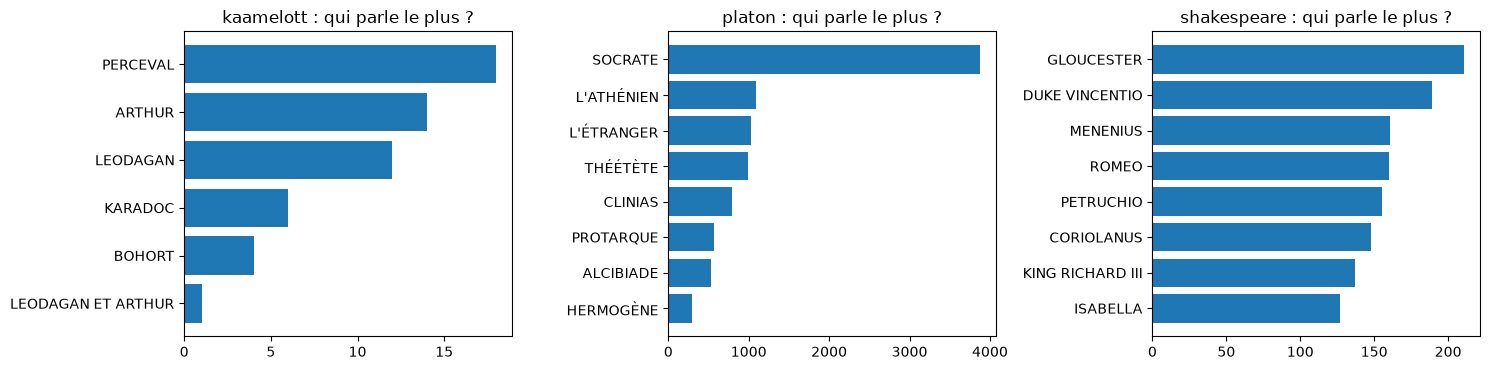

In [4]:
groupes = {nom: ft.lire_dialogues(nom) for nom in CORPORA}

print(f"{'corpus':12s} {'groupes':>8s} {'répliques':>10s} {'personnages':>12s} {'car./réplique (médiane)':>24s}")
for nom, gs in groupes.items():
    reps = [r for g in gs for r in g]
    print(f"{nom:12s} {len(gs):8d} {len(reps):10,} {len({r.personnage for r in reps}):12,} {statistics.median(len(r.texte) for r in reps):24.0f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (nom, gs) in zip(axes, groupes.items()):
    top = Counter(r.personnage for g in gs for r in g).most_common(8)
    ax.barh([p for p, _ in top][::-1], [n for _, n in top][::-1])
    ax.set_title(f"{nom} : qui parle le plus ?")
plt.tight_layout(); plt.show()

**Kaamelott est minuscule** : 7 scènes, une cinquantaine de répliques. C'est un extrait volontairement court (même fichier qu'au chapitre 2). Il suffit pour **voir** un fine-tuning fonctionner — et pour voir un modèle mémoriser. Pour un vrai projet, le dataset Kaggle complet de la série (> 30 000 répliques, voir le devoir) serait nécessaire.

Platon est dominé par **Socrate** (et l'« Athénien » des *Lois*) : un modèle fine-tuné aura tendance à faire parler Socrate. C'est un **biais du dataset**, pas du modèle.

---
## 3. Le split : par groupe, jamais par ligne

Au chapitre 2, on coupait le texte **dans l'ordre** (90 % / 10 %) pour que la validation contienne du texte jamais vu. Ici, chaque exemple contient **les 3 répliques précédentes** comme contexte. Si on tire les exemples au hasard, la réplique à prédire en validation apparaît… dans le **contexte** d'un exemple d'entraînement voisin. Mesurons-le.

In [5]:
def taux_de_fuite(train, val):
    """Part des réponses de validation qu'on retrouve mot pour mot dans un prompt d'entraînement."""
    contextes = "\n".join(e["prompt"][0]["content"] for e in train)
    return np.mean([e["completion"][0]["content"] in contextes for e in val])

for nom in CORPORA:
    tous = ft.construire_exemples(groupes[nom], nom)
    melange = tous[:]
    random.Random(0).shuffle(melange)
    n_val = len(melange) // 10
    fuite_hasard = taux_de_fuite(melange[n_val:], melange[:n_val])

    g_train, g_val = ft.separer_par_groupe(groupes[nom], part_val=0.2 if nom == "kaamelott" else 0.1)
    fuite_groupe = taux_de_fuite(ft.construire_exemples(g_train, nom), ft.construire_exemples(g_val, nom))
    print(f"{nom:12s} split au hasard : {fuite_hasard:6.1%} de fuite | split par groupe : {fuite_groupe:5.1%}")

kaamelott    split au hasard : 100.0% de fuite | split par groupe :  0.0%


platon       split au hasard :  96.4% de fuite | split par groupe :  8.2%


shakespeare  split au hasard :  95.4% de fuite | split par groupe :  0.2%


Avec un split au hasard, **presque toutes** les réponses de validation ont été vues pendant l'entraînement (dans un contexte). La loss de validation serait excellente… et ne mesurerait rien. Le split **par groupe** (scène, dialogue, bloc) réserve des scènes **entières** à la validation : on mesure la capacité à continuer une scène **inédite**.

Ce qui reste avec le split par groupe (8 % pour Platon, presque rien ailleurs) vient de répliques **qui se répètent** dans le corpus (« Oui. », « Certainement. »…) : elles apparaissent légitimement dans plusieurs dialogues.

Pour Kaamelott, on réserve 20 % (une ou deux scènes) : avec 10 %, la validation ne contiendrait qu'une poignée de répliques.

---
## 4. Construire les exemples

`ft.construire_exemples` transforme chaque réplique (sauf la première d'un groupe) en exemple :
- **prompt** : la consigne + les `k = 3` répliques précédentes, au format `NOM: texte` ;
- **réponse** : `NOM: réplique`. Le modèle doit donc aussi choisir **qui parle**.

Deux garde-fous de longueur : une réplique de contexte trop longue est **tronquée par le début** (`… ` + la fin, la partie la plus utile pour enchaîner), et une réponse de plus de 600 caractères est écartée (on n'apprend pas à écrire des monologues de deux pages).

In [6]:
PART_VAL = {"kaamelott": 0.2, "platon": 0.1, "shakespeare": 0.1}
datasets = {}
for nom in CORPORA:
    g_train, g_val = ft.separer_par_groupe(groupes[nom], part_val=PART_VAL[nom], graine=42)
    train = ft.dedoublonner(ft.construire_exemples(g_train, nom, k=3))
    val = ft.dedoublonner(ft.construire_exemples(g_val, nom, k=3))
    datasets[nom] = (train, val)
    print(f"{nom:12s} train : {len(train):5,} exemples | val : {len(val):4,} exemples "
          f"| réponses de val identiques à une réponse de train : {len(ft.fuites(train, val))}")

exemple = datasets["platon"][0][123]
print("\n--- un exemple Platon ---")
print(json.dumps({k: exemple[k] for k in ("prompt", "completion")}, ensure_ascii=False, indent=1))

kaamelott    train :    38 exemples | val :   10 exemples | réponses de val identiques à une réponse de train : 0
platon       train : 8,335 exemples | val : 1,013 exemples | réponses de val identiques à une réponse de train : 55


shakespeare  train : 6,013 exemples | val :  665 exemples | réponses de val identiques à une réponse de train : 0

--- un exemple Platon ---
{
 "prompt": [
  {
   "role": "user",
   "content": "Continue ce dialogue de Platon (traduction de Victor Cousin) avec la réplique suivante.\n\nHERMOGÈNE: Assurément.\nSOCRATE: Peux-tu m'en dire autant au sujet du nom ? Si c'est un instrument, qu'en faisons-nous quand nous nommons ?\nHERMOGÈNE: C'est ce que je ne puis dire."
  }
 ],
 "completion": [
  {
   "role": "assistant",
   "content": "SOCRATE: N'est-ce pas que nous nous apprenons quelque chose les uns aux autres, et que nous démêlons les manières d'être des divers objets ?"
  }
 ]
}


In [7]:
for e in ft.fuites(*datasets["platon"])[:8]:
    print(repr(e["completion"][0]["content"]))

'CLINIAS: Sans doute.'
'CLINIAS: Nécessairement.'
'CLINIAS: Il y a toute apparence.'
'CLINIAS: Tu as raison.'
'CLINIAS: Tu as parfaitement raison.'
'CLINIAS: Cela est certain.'
'CLINIAS: Rien de plus vrai.'
'CLINIAS: Cela est vraisemblable.'


Les « fuites » restantes de Platon sont des **formules** du dialogue socratique. Elles sont légitimes (le modèle doit apprendre que l'interlocuteur acquiesce souvent !), mais il faut savoir qu'elles existent : elles rendent la validation un peu optimiste. Ce n'est pas le cas des **quasi-doublons** (même réplique avec une ponctuation différente) qu'une recherche par n-grammes ou MinHash permettrait de trouver — exercice du devoir.

---
## 5. Passer au format de Mistral et compter les tokens

Le modèle ne voit pas un dictionnaire Python mais une **chaîne** formatée par le *chat template* (notebook 01, §4). Mesurons la longueur de chaque exemple **en tokens**, pour choisir `max_length` — la longueur maximale d'une séquence pendant l'entraînement.

In [8]:
MODEL_ID = "mistralai/Mistral-7B-Instruct-v0.3"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

print(tokenizer.apply_chat_template(exemple["prompt"] + exemple["completion"], tokenize=False))

def n_tokens(e):
    return len(tokenizer.apply_chat_template(e["prompt"] + e["completion"])["input_ids"])

longueurs = {nom: np.array([n_tokens(e) for e in train]) for nom, (train, val) in datasets.items()}

<s>[INST] Continue ce dialogue de Platon (traduction de Victor Cousin) avec la réplique suivante.

HERMOGÈNE: Assurément.
SOCRATE: Peux-tu m'en dire autant au sujet du nom ? Si c'est un instrument, qu'en faisons-nous quand nous nommons ?
HERMOGÈNE: C'est ce que je ne puis dire.[/INST] SOCRATE: N'est-ce pas que nous nous apprenons quelque chose les uns aux autres, et que nous démêlons les manières d'être des divers objets ?</s>


corpus          p50    p90    p95    p99    max   > 512 tokens
kaamelott       131    155    160    181    192     0.0%
platon          185    342    401    530    749     1.3%
shakespeare     162    303    348    430    579     0.1%


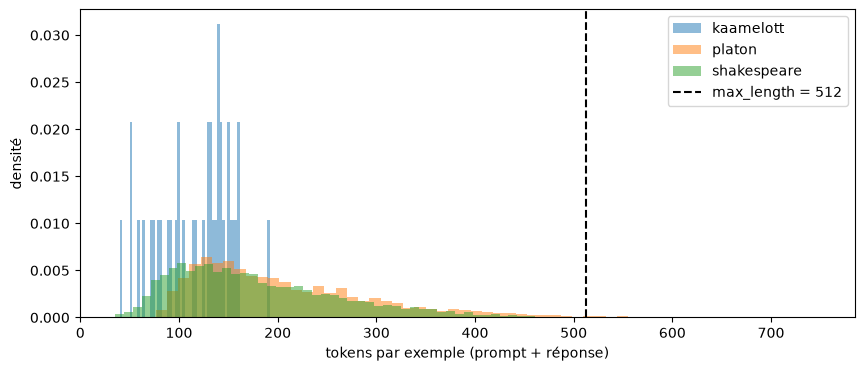

In [9]:
print(f"{'corpus':12s} {'p50':>6s} {'p90':>6s} {'p95':>6s} {'p99':>6s} {'max':>6s}   > 512 tokens")
for nom, L in longueurs.items():
    p = np.percentile(L, [50, 90, 95, 99])
    print(f"{nom:12s} " + " ".join(f"{x:6.0f}" for x in p) + f" {L.max():6d}   {np.mean(L > 512):6.1%}")

fig, ax = plt.subplots(figsize=(10, 4))
for nom, L in longueurs.items():
    ax.hist(L, bins=60, alpha=0.5, density=True, label=nom)
ax.axvline(512, color="black", ls="--", label="max_length = 512")
ax.set_xlabel("tokens par exemple (prompt + réponse)"); ax.set_ylabel("densité"); ax.legend()
plt.show()

**Choix : `max_length = 512`.** Il couvre la quasi-totalité des exemples (on mesure, on ne choisit pas « 2048 par habitude »). Les rares exemples plus longs seront **tronqués** par la fin : ils perdent la fin de leur réponse, ce qui est acceptable pour 1 % des données.

Pourquoi ne pas prendre 32 768, la fenêtre de Mistral ? La mémoire des **activations** grandit avec la longueur des séquences (notebook 04), et on paierait pour du *padding*. La bonne valeur vient de la distribution des données, pas de la fiche technique du modèle.

### Combien de tokens d'entraînement ?

Le coût d'un fine-tuning est proportionnel au **nombre de tokens traités** (notebook 05) :

In [10]:
for nom, L in longueurs.items():
    print(f"{nom:12s} {len(L):6,} exemples, {L.sum():>10,} tokens par époque (moyenne {L.mean():.0f} tokens/exemple)")

kaamelott        38 exemples,      4,433 tokens par époque (moyenne 117 tokens/exemple)
platon        8,335 exemples,  1,749,733 tokens par époque (moyenne 210 tokens/exemple)
shakespeare   6,013 exemples,  1,084,945 tokens par époque (moyenne 180 tokens/exemple)


Sur un GPU T4 de Colab, un QLoRA de Mistral 7B traite de l'ordre de quelques centaines de tokens par seconde : une époque complète de Platon ou de Shakespeare prendrait plusieurs heures. Au notebook 05, on entraînera donc sur un **sous-échantillon** (quelques centaines à un millier d'exemples) : l'objectif en cours est de voir **le pipeline complet**, pas d'obtenir le meilleur modèle.

---
## 6. Exporter

Un exemple par ligne, au format JSON (*JSON Lines*). Les champs `prompt` / `completion` sont ceux qu'attend la bibliothèque TRL ; `personnage` et `groupe` servent à l'analyse. Ces fichiers sont versionnés dans le dépôt : le notebook 05, sur Colab, les télécharge directement.

In [11]:
from pathlib import Path
for nom, (train, val) in datasets.items():
    ft.sauver_jsonl(train, f"data/{nom}_train.jsonl")
    ft.sauver_jsonl(val, f"data/{nom}_val.jsonl")
for f in sorted(Path("data").glob("*.jsonl")):
    print(f"{str(f):32s} {f.stat().st_size / 1e6:6.2f} Mo  {sum(1 for _ in f.open()):6,} exemples")

relu = ft.charger_jsonl("data/kaamelott_val.jsonl")
print("\nRelecture :", relu[0]["completion"])

data/kaamelott_train.jsonl         0.02 Mo      38 exemples
data/kaamelott_val.jsonl           0.01 Mo      10 exemples
data/platon_train.jsonl            6.43 Mo   8,335 exemples
data/platon_val.jsonl              1.09 Mo   1,013 exemples
data/shakespeare_train.jsonl       4.41 Mo   6,013 exemples
data/shakespeare_val.jsonl         0.49 Mo     665 exemples

Relecture : [{'role': 'assistant', 'content': 'ARTHUR: Ben attendez ! J’vais vous rendre la votre !'}]


## À retenir

- Un corpus brut n'est **pas** un dataset : défauts d'extraction, répliques vides, artefacts CSV, monologues. On **regarde** avant d'entraîner.
- Le split se fait **par groupe** (scène, dialogue) : un split au hasard fait fuiter ~100 % des réponses de validation dans les contextes d'entraînement.
- Un exemple de SFT = `prompt` (consigne + contexte) → `completion` (réplique suivante). La construction de ces couples **définit la tâche**.
- `max_length` se choisit sur la **distribution des longueurs en tokens** (ici 512).
- Le coût se compte en **tokens**, pas en lignes.

**Questions de vérification**
1. Pourquoi les blocs de 40 répliques de Shakespeare sont-ils un pis-aller ? Quel serait le groupe idéal ?
2. Que mesurerait la loss de validation si on avait fait un split au hasard ?
3. Pourquoi tronquer une réplique de **contexte** par le **début** plutôt que par la fin ?
4. Le personnage de la réponse fait partie de la cible (`KARADOC: ...`). Quel comportement cela apprend-il au modèle ? Que changerait le mode `"personnage"` ?